# Cleaning Messy Data + Ridge Regression

A messy 1,300-row regression dataset (response `y`, predictors `x1`–`x9`) with duplicates, numbers stored as text, missing values, and outliers. I clean it step by step, then fit ridge regression across a range of λ values to see how the penalty shrinks each coefficient, and compare ridge at λ = 0 with ordinary linear regression.


### Data Cleaning

Four problems found and fixed: duplicate rows, inconsistent data types, missing values, and outliers.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# configure matplotlib for display 
%matplotlib inline
plt.rc("figure", figsize=(10, 6))

dataset = pd.read_csv('data/messy_regression_data.csv')
print(dataset.head())

num_rows = len(dataset)
print(num_rows)

                     y                   x1        x2                    x3  \
0   -4.693610217747385  -0.5519386424232415 -0.340243   -1.0808708745904039   
1   -15.86969087114172    -2.98693819987046  2.081854   -1.7334794646948888   
2    1.288319246430799                  NaN -0.118363  -0.05342016489962721   
3  -2.6005560199932356  -0.5366794042855869  0.459774    -0.568994434432151   
4  -1.6292055960862437  -0.7685235481410445  0.846460   0.29299993619404174   

         x4                    x5                    x6        x7        x8  \
0       NaN   -0.5403289171911252   -0.7201471430609068 -2.910121 -0.367100   
1  0.971255                   NaN     4.184723965457835 -2.755510 -0.473597   
2 -0.719797  -0.12316758269249779  -0.28386431257811007  0.666960 -0.129895   
3  0.579335   -0.5591978138484204    0.8795330702791521 -1.087294 -0.031008   
4 -0.739847   -0.7785521071738329    1.7641158113699278       NaN  0.013733   

                     x9  
0   -1.9289652385759224 

In [2]:
# problem 1: duplicate rows
# count total number of duplicate rows
num_duplicates = dataset.duplicated().sum()
print(num_duplicates) # there are 53 duplicate rows

# keep only the last occurrence of a duplicate row 
dataset_cl = dataset.drop_duplicates(keep='last')
num_rows = len(dataset_cl)
print(num_rows) # rows reduced from 1300 to 1247

53
1247


In [3]:
# problem 2: inconsistent data types
# check current data types
print("Current data types:")
print(dataset_cl.dtypes) # we have both object and float64

# convert all columns to float, handling errors
dataset_cl = dataset_cl.apply(pd.to_numeric, errors='coerce')
print(dataset_cl.dtypes) # all are now float64 data type

Current data types:
y      object
x1     object
x2    float64
x3     object
x4    float64
x5     object
x6     object
x7    float64
x8    float64
x9     object
dtype: object
y     float64
x1    float64
x2    float64
x3    float64
x4    float64
x5    float64
x6    float64
x7    float64
x8    float64
x9    float64
dtype: object


In [4]:
# problem 3: missing values
# missing values per column
missing_per_column = dataset_cl.isnull().sum()
print("Missing values per column:")
print(missing_per_column)

# fill missing values with median
dataset_cl = dataset_cl.fillna(dataset_cl.median())
missing_per_column = dataset_cl.isnull().sum()

Missing values per column:
y      1
x1    67
x2    60
x3    61
x4    47
x5    67
x6    49
x7    71
x8    60
x9    63
dtype: int64


In [5]:
# problem 4: outliers
# remove outliers using IQR method
Q1 = dataset_cl.quantile(0.25)  # 25th percentile
Q3 = dataset_cl.quantile(0.75)  # 75th percentile
IQR = Q3 - Q1  # Interquartile range

# define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# identify outliers (any value outside bounds in any column)
keep_rows = ((dataset_cl >= lower_bound) & (dataset_cl <= upper_bound)).all(axis=1)

# remove outliers
dataset_clean = dataset_cl[keep_rows]

# summary
print(f"After removing outliers: {len(dataset_clean)} ({len(dataset_cl) - len(dataset_clean)} rows removed)")

After removing outliers: 1157 (90 rows removed)


### Ridge coefficient paths


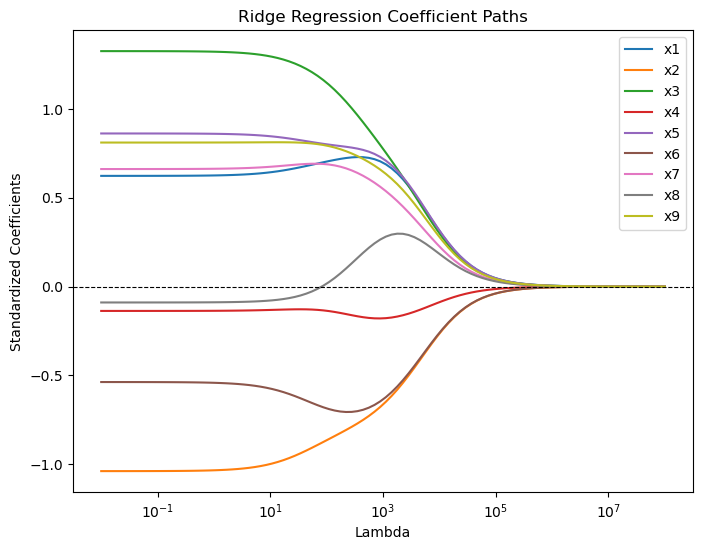

In [6]:
from sklearn.linear_model import Ridge # for ridge regression
from sklearn.preprocessing import StandardScaler # to standardize the data
import matplotlib.pyplot as plt

# separate X and y (response from predictor)
y = dataset_clean['y']
X = dataset_clean.drop('y', axis=1)

# standardize predictors (equation 6.6 in textbook)
scaler = StandardScaler() # creates the standardization tool
X_standardized = scaler.fit_transform(X) # applies the formula: (x - mean)/std

# range of lambda values (alpha in sklearn)
lambdas = 10**np.linspace(-2, 8, 100)

# store coefficients for each lambda
coefs = []
for i in lambdas:
    ridge = Ridge(alpha=i)
    ridge.fit(X_standardized, y)
    coefs.append(ridge.coef_)

coefs = np.array(coefs)

# plot coefficient paths
plt.figure(figsize=(8, 6))
for i in range(X.shape[1]):
    plt.plot(lambdas, coefs[:, i], label=X.columns[i])

plt.xscale('log')
plt.xlabel('Lambda')
plt.ylabel('Standardized Coefficients')
plt.title('Ridge Regression Coefficient Paths')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend()
plt.show()

### Discussion

#### 1. How does ridge regression relate to linear regression?


Answer: 
Ridge regression is basically just linear regression with an extra penalty term added on. Regular linear regression tries to minimize the sum of squared errors to fit the data as closely as possible. Ridge regression does the same thing, but it also adds a penalty term that shrinks the coefficients toward zero. When λ = 0, ridge regression is exactly the same as regular linear regression because there's no penalty. But as λ increases, the coefficients get smaller, which helps reduce overfitting and makes the model more stable. Ridge regression is useful when we have a lot of predictors or when regular linear regression gives us coefficients that are too large and unstable.

#### 2. What does the parameter $\lambda$ do?


Answer: 
The parameter λ controls how much we penalize large coefficients in ridge regression. When λ is close to 0, the penalty isn't strong, so the coefficients stay close to their original linear regression values. When λ is large, the penalty is strong, so all the coefficients shrink toward zero, which helps prevent overfitting by keeping the model from relying too heavily on any single predictor. This creates a bias-variance tradeoff where, as λ increases, we introduce more bias but reduce variance. The optimal λ balances these two to minimize overall test error.

#### 3. Why look at *standardized* coefficients?


Answer: 
We're interested in standardized coefficients because ridge regression is sensitive to the scale of the predictors. By standardizing all predictors to have a mean of 0 and a standard deviation of 1, we put everything on the same scale, which makes the coefficients comparable and ensures that the penalty affects all variables fairly. This way, the shrinkage depends on the actual importance of the variable, not just its measurement units. Without standardization, variables measured in larger units would be penalized less because of their scale, leading to inconsistent results. Additionally, standardized coefficients allow us to directly compare the relative importance of predictors, as a one-unit change represents a one standard deviation change for all variables.

#### 4. Is the ridge coefficient for $x_6$ at $\lambda=0$ the same as the linear regression coefficient?


In [7]:
# fit ordinary linear regression for comparison
from sklearn.linear_model import LinearRegression # for linear regression

# separate X and y
y = dataset_clean['y']
X = dataset_clean.drop('y', axis=1)

# standardize
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X) # standardizes all predictors (mean = 0, sd = 1)

# linear regression (standardized)
lin_model = LinearRegression() # create a linear regression model
lin_model.fit(X_standardized, y) # train model on standardized data
lin_coef_x6 = lin_model.coef_[5] # get coef for x6 (index 5)

# ridge with λ=0 (standardized)
ridge_model = Ridge(alpha=0) # create ridge regression with λ=0 (no penalty)
ridge_model.fit(X_standardized, y) # train model on same standardized data
ridge_coef_x6 = ridge_model.coef_[5]

# compare standardized linear regression with standardized ridge regression
print(f"Linear regression x6: {lin_coef_x6:.5f}")
print(f"Ridge (λ=0) x6: {ridge_coef_x6:.5f}")

Linear regression x6: -0.53700
Ridge (λ=0) x6: -0.53700


Answer:
Yes, ridge with λ = 0 equals linear regression. The output shows that the x6 coefficient is the same in both models. This happens because when λ = 0, there is no penalty, so ridge regression minimizes the same objective function as linear regression. The x6 coefficient tells us how much Y changes when X6 increases by one standard deviation. Since both models minimize the same equation using the same data, they give the same coefficients. This demonstrates that ridge regression with λ = 0 is equivalent to regular linear regression.